# A10 - Learning the Kinect 2D from movenet 2D Skeleton Avatars

Maps movenet 2D joint coordinates (x_pn, y_pn) to Kinect 2D joint coordinates (x_k, y_k).

**Data:** movenet CSVs generated from Kinect videos (`data/raw/movenet/movenet/csv_output`). Kinect CSVs provide the 2D targets.

- **Input:** 13 joints x 2 = 26 movenet features (pixel coordinates)
- **Target:** 13 joints x 2 = 26 Kinect features (meters)
- **Framework:** PyTorch
- **Models:** Dense (32 / 64 / 128 hidden nodes), with and without horizontal-flip augmentation

**Deep Learning steps:**
1. Load and prepare matched Kinect + movenet frame sequences
2. Define a Dense network
3. Compile (MSE loss, Adam)
4. Split with k-fold cross-validation
5. Train with early stopping
6. Evaluate per-joint Euclidean distance in cm

## Imports and configuration

In [3]:
import torch
print(torch.__version__)
print(torch.version.cuda)
#print(torch.cuda.get_device_name(0))
#print(torch.cuda.get_device_capability(0))


2.7.1
None


In [25]:
from pathlib import Path
import os, random, warnings, copy, json
import mlflow
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

SEQ_LEN          = 20
STRIDE           = 1
N_SPLITS         = 10
VALIDATION_SPLIT = 0.10
BATCH_SIZE       = 32
EPOCHS           = 100
PATIENCE         = 10
LEARNING_RATE    = 1e-3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

KINECT_DIR  = Path("../../../data/raw/kinect_good_preprocessed")
MOVENET_DIR = Path("../../../data/raw/movenet/movenet/csv_output")


JOINTS = [
    "head", "left_shoulder", "left_elbow", "right_shoulder", "right_elbow",
    "left_hand", "right_hand", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_foot", "right_foot",
]

INPUT_FEATURES  = [f"{j}_pn_{ax}" for j in JOINTS for ax in ["x", "y"]]
TARGET_FEATURES = [f"{j}_{ax}"    for j in JOINTS for ax in ["x", "y"]]

TARGET_UNIT = "meters"

def to_cm(v): return v * 100.0

print("PyTorch:", torch.__version__, "| Device:", DEVICE)
print("Input features:", len(INPUT_FEATURES), "| Target features:", len(TARGET_FEATURES))

PyTorch: 2.7.1 | Device: cpu
Input features: 26 | Target features: 26


In [5]:
FRAME_CANDIDATES = ["FrameNo", "frame", "frame_no", "Frame", "frameno", "frame_index"]
SEQ_CANDIDATES   = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]


def read_csv_file(path):
    s = path.suffix.lower()
    if s == ".csv":  return pd.read_csv(path)
    if s == ".tsv":  return pd.read_csv(path, sep="\t")
    if s in (".xlsx", ".xls"): return pd.read_excel(path)
    raise ValueError(f"Unsupported: {path}")


def standardize_cols(df):
    return df.rename(columns={c: c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns})


def find_col(df, candidates):
    low = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in low: return low[cand.lower()]
    return None


def load_dir(data_dir, skip_stems=()):
    if not data_dir.exists():
        raise FileNotFoundError(f"Directory not found: {data_dir}")
    files = sorted(data_dir.glob("*.csv")) + sorted(data_dir.glob("*.tsv"))
    files = [f for f in files if f.stem not in skip_stems]
    if not files:
        raise FileNotFoundError(f"No CSV files in {data_dir}")
    dfs = []
    for p in files:
        df = standardize_cols(read_csv_file(p))
        seq_col = find_col(df, SEQ_CANDIDATES)
        df["sequence_id"] = df[seq_col] if seq_col else p.stem
        frame_col = find_col(df, FRAME_CANDIDATES)
        df["frameno"] = df[frame_col] if frame_col else np.arange(len(df))
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


def seq_key(sid):
    for sfx in ("_kinect", "_posenet", "_pose"):
        if sid.endswith(sfx): return sid[:-len(sfx)]
    return sid


kinect_raw  = load_dir(KINECT_DIR);  kinect_raw["seq_key"]  = kinect_raw["sequence_id"].apply(seq_key)
movenet_raw = load_dir(MOVENET_DIR); movenet_raw["seq_key"] = movenet_raw["sequence_id"].apply(seq_key)

print("Kinect:", kinect_raw.shape, "| MoveNet:", movenet_raw.shape)

Kinect: (24005, 42) | MoveNet: (38248, 56)


In [6]:
# Drop score columns and timestamp (not joint coordinates)
drop_cols = [c for c in movenet_raw.columns if c.endswith("_score") or c == "timestamp_ms"]
movenet_raw = movenet_raw.drop(columns=drop_cols, errors="ignore")

# Map MoveNet joint names to our standard names used in JOINTS
MOVENET_TO_STANDARD = {
    "nose":         "head",
    "left_wrist":   "left_hand",
    "right_wrist":  "right_hand",
    "left_ankle":   "left_foot",
    "right_ankle":  "right_foot",
}
joint_rename = {}
for old, new in MOVENET_TO_STANDARD.items():
    for ax in ["x", "y"]:
        joint_rename[f"{old}_{ax}"] = f"{new}_{ax}"
movenet_raw = movenet_raw.rename(columns=joint_rename)

# Rename joint x/y columns to _pn_ convention: head_x -> head_pn_x, etc.
pn_base = [f"{j}_{ax}" for j in JOINTS for ax in ["x", "y"]]
pn_rename = {c: c.rsplit("_", 1)[0] + "_pn_" + c.rsplit("_", 1)[1] for c in pn_base if c in movenet_raw.columns}
movenet_renamed = movenet_raw.rename(columns=pn_rename)

missing_pn = [c for c in INPUT_FEATURES  if c not in movenet_renamed.columns]
missing_k  = [c for c in TARGET_FEATURES if c not in kinect_raw.columns]
if missing_pn: raise ValueError(f"Missing MoveNet columns: {missing_pn[:5]}")
if missing_k:  raise ValueError(f"Missing Kinect columns: {missing_k}")

kinect_slim  = kinect_raw[["seq_key", "frameno"] + TARGET_FEATURES].copy()
movenet_slim = movenet_renamed[["seq_key", "frameno"] + INPUT_FEATURES].copy()

df = (pd.merge(kinect_slim, movenet_slim, on=["seq_key", "frameno"], how="inner")
        .rename(columns={"seq_key": "sequence_id"})
        .sort_values(["sequence_id", "frameno"])
        .reset_index(drop=True))

print("Merged shape:", df.shape, "| Sequences:", df["sequence_id"].nunique())
display(df.head())

Merged shape: (24005, 54) | Sequences: 179


,sequence_id,frameno,head_x,head_y,left_shoulder_x,left_shoulder_y,left_elbow_x,left_elbow_y,right_shoulder_x,right_shoulder_y,...,right_hip_pn_x,right_hip_pn_y,left_knee_pn_x,left_knee_pn_y,right_knee_pn_x,right_knee_pn_y,left_foot_pn_x,left_foot_pn_y,right_foot_pn_x,right_foot_pn_y
0,A1,68,0.012479,0.77345,-0.13806,0.56134,-0.23846,0.78626,0.16386,0.53453,...,931.65,572.81,1046.87,814.21,897.37,818.35,1051.84,1017.76,894.99,997.56
1,A1,69,0.012189,0.77359,-0.13808,0.56113,-0.23875,0.78576,0.16382,0.53451,...,932.37,571.68,1046.90,815.42,898.36,820.01,1051.59,1018.28,894.59,996.47
2,A1,70,0.011877,0.77387,-0.13805,0.56091,-0.23911,0.78529,0.16376,0.53471,...,932.68,573.55,1046.65,817.84,901.12,822.01,1050.97,1018.95,901.34,1003.84
3,A1,71,0.011558,0.77405,-0.13800,0.56081,-0.23967,0.78489,0.16366,0.53504,...,933.92,574.18,1047.84,818.79,902.39,823.25,1050.83,1018.45,901.52,1004.92
4,A1,72,0.011211,0.77415,-0.13795,0.56081,-0.24036,0.78463,0.16347,0.53560,...,929.22,575.75,1052.58,829.87,901.81,823.35,1050.91,1025.96,893.62,1004.68


## Step 2: Build fixed-length sequences

In [7]:
def build_sequences(df, input_cols, target_cols, seq_len=20, stride=1):
    X_list, y_list, sid_list = [], [], []
    clean = df.dropna(subset=input_cols + target_cols)
    for sid, group in clean.groupby("sequence_id"):
        group = group.sort_values("frameno").reset_index(drop=True)
        if len(group) < seq_len: continue
        xv = group[input_cols].to_numpy(dtype=np.float32)
        yv = group[target_cols].to_numpy(dtype=np.float32)
        for s in range(0, len(group) - seq_len + 1, stride):
            X_list.append(xv[s:s+seq_len])
            y_list.append(yv[s:s+seq_len])
            sid_list.append(sid)
    return np.array(X_list, np.float32), np.array(y_list, np.float32), np.array(sid_list)


X, y, seq_ids = build_sequences(df, INPUT_FEATURES, TARGET_FEATURES, SEQ_LEN, STRIDE)

print("X shape:", X.shape, " (sequences, frames, posenet_features)")
print("y shape:", y.shape, " (sequences, frames, kinect_features)")

X shape: (20604, 20, 26)  (sequences, frames, posenet_features)
y shape: (20604, 20, 26)  (sequences, frames, kinect_features)


In [8]:
target_summary = pd.DataFrame(y.reshape(-1, len(TARGET_FEATURES)), columns=TARGET_FEATURES).describe().T[["mean","std","min","max"]]
display(target_summary)

,mean,std,min,max
head_x,-0.005146,0.029639,-0.219620,0.227100
head_y,0.458115,0.274863,-0.286400,0.866600
left_shoulder_x,-0.152507,0.027670,-0.315020,0.057288
left_shoulder_y,0.264977,0.265282,-0.430780,0.669560
left_elbow_x,-0.268805,0.059581,-0.479500,-0.008361
left_elbow_y,0.448973,0.287816,-0.271150,0.923650
right_shoulder_x,0.152825,0.031542,0.013050,0.325720
right_shoulder_y,0.264747,0.260398,-0.393830,0.650950
right_elbow_x,0.274780,0.063021,0.101260,0.487550
right_elbow_y,0.449804,0.281946,-0.232920,0.898130


## Data augmentation horizontal flip

Mirror every sequence left right to double the dataset.
- PoseNet x: `1920 - x_pn` (pixel mirror across image centre)
- Kinect x: `-x_k` (body coords are centred, so mirror = negate x)
- Left/right joint labels are swapped (left_shoulder â†” right_shoulder, etc.)

In [9]:
SWAP_PAIRS = [
    ("left_shoulder", "right_shoulder"),
    ("left_elbow",    "right_elbow"),
    ("left_hand",     "right_hand"),
    ("left_hip",      "right_hip"),
    ("left_knee",     "right_knee"),
    ("left_foot",     "right_foot"),
]

def horizontal_flip(X, y):
    X_f = X.copy()
    y_f = y.copy()

    for j in JOINTS:
        col = INPUT_FEATURES.index(f"{j}_pn_x")
        X_f[:, :, col] = 1920 - X[:, :, col]

    for j in JOINTS:
        col = TARGET_FEATURES.index(f"{j}_x")
        y_f[:, :, col] = -y[:, :, col]

    for left_j, right_j in SWAP_PAIRS:
        for ax in ["x", "y"]:
            lc = INPUT_FEATURES.index(f"{left_j}_pn_{ax}")
            rc = INPUT_FEATURES.index(f"{right_j}_pn_{ax}")
            X_f[:, :, lc], X_f[:, :, rc] = X_f[:, :, rc].copy(), X_f[:, :, lc].copy()

            lc = TARGET_FEATURES.index(f"{left_j}_{ax}")
            rc = TARGET_FEATURES.index(f"{right_j}_{ax}")
            y_f[:, :, lc], y_f[:, :, rc] = y_f[:, :, rc].copy(), y_f[:, :, lc].copy()

    return X_f, y_f

# Keep originals for the no-augmentation baseline
X_orig, y_orig, seq_ids_orig = X.copy(), y.copy(), seq_ids.copy()

X_flip, y_flip = horizontal_flip(X, y)
X       = np.concatenate([X, X_flip])
y       = np.concatenate([y, y_flip])
seq_ids = np.concatenate([seq_ids, seq_ids])  # flipped windows keep same sequence ID
print(f"Original:           X={X_orig.shape}, seq_ids={seq_ids_orig.shape}")
print(f"After augmentation: X={X.shape}, y={y.shape}, seq_ids={seq_ids.shape}  (doubled)")

Original:           X=(20604, 20, 26), seq_ids=(20604,)
After augmentation: X=(41208, 20, 26), y=(41208, 20, 26), seq_ids=(41208,)  (doubled)


## Dataset and scaling

In [10]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


def fit_scaler(X_train):
    s = StandardScaler()
    s.fit(X_train.reshape(-1, X_train.shape[-1]))
    return s


def apply_scaler(X, s):
    return s.transform(X.reshape(-1, X.shape[-1])).reshape(X.shape).astype(np.float32)


def make_loader(X_, y_, shuffle):
    return DataLoader(SequenceDataset(X_, y_), batch_size=BATCH_SIZE, shuffle=shuffle)

## Step 2: Define the model

Dense network with one hidden layer (64 nodes, ReLU).
Flattens (seq_len x features) -> hidden -> (seq_len x targets).

In [11]:
class DensePoseRegressor(nn.Module):
    def __init__(self, seq_len, n_in, n_out, hidden_units=(64,), dropout=0.0):
        super().__init__()
        layers, prev = [], seq_len * n_in
        for h in hidden_units:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, seq_len * n_out))
        self.net = nn.Sequential(*layers)
        self.seq_len, self.n_out = seq_len, n_out

    def forward(self, x):
        b = x.shape[0]
        return self.net(x.reshape(b, -1)).reshape(b, self.seq_len, self.n_out)


_m = DensePoseRegressor(SEQ_LEN, len(INPUT_FEATURES), len(TARGET_FEATURES))
print("Output shape:", _m(torch.zeros(2, SEQ_LEN, len(INPUT_FEATURES))).shape)  # expect (2, 20, 26)
print(_m)

Output shape: torch.Size([2, 20, 26])
DensePoseRegressor(
  (net): Sequential(
    (0): Linear(in_features=520, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=520, bias=True)
  )
)


## Step 3: Training helpers (MSE loss, Adam, early stopping)

In [12]:
def eval_metrics(model, loader, criterion):
    """Returns (mse_loss, mae) averaged over the loader."""
    model.eval()
    total_mse, total_mae, n = 0.0, 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            total_mse += criterion(pred, yb).item() * xb.size(0)
            total_mae += torch.mean(torch.abs(pred - yb)).item() * xb.size(0)
            n += xb.size(0)
    return total_mse / max(n, 1), total_mae / max(n, 1)


def predict(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(DEVICE)).cpu().numpy())
            trues.append(yb.numpy())
    return np.concatenate(trues), np.concatenate(preds)


def per_joint_dist_cm(y_true, y_pred, n_joints=len(JOINTS)):
    t = y_true.reshape(-1, n_joints, 2)
    p = y_pred.reshape(-1, n_joints, 2)
    return to_cm(np.sqrt(((t - p) ** 2).sum(axis=2)).mean(axis=0))


def train_model(model, train_loader, val_loader):
    model = model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    best_state = copy.deepcopy(model.state_dict())
    best_val   = float("inf")
    best_epoch = 0
    wait       = 0
    history    = {"train_loss": [], "val_loss": [], "train_mae": [], "val_mae": []}

    for epoch in range(EPOCHS):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()

        tl, tm = eval_metrics(model, train_loader, criterion)
        vl, vm = eval_metrics(model, val_loader,   criterion)
        history["train_loss"].append(tl)
        history["val_loss"].append(vl)
        history["train_mae"].append(tm)
        history["val_mae"].append(vm)

        if vl < best_val:
            best_val, best_epoch = vl, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE: break

    model.load_state_dict(best_state)
    return model, history, best_val, best_epoch

## Step 4-5: k-fold cross-validation

In [13]:
def run_cv(X, y, seq_ids, cfg):
    unique_seqs = np.unique(seq_ids)
    kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    fold_results, fold_histories = [], []

    for fi, (tv_seq_idx, test_seq_idx) in enumerate(kf.split(unique_seqs), 1):
        tv_seqs   = unique_seqs[tv_seq_idx]
        test_seqs = unique_seqs[test_seq_idx]

        tv_mask   = np.isin(seq_ids, tv_seqs)
        test_mask = np.isin(seq_ids, test_seqs)

        X_tv,   y_tv   = X[tv_mask],   y[tv_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        # Val split also at sequence level to avoid overlap
        tr_seqs, val_seqs = train_test_split(
            tv_seqs, test_size=VALIDATION_SPLIT, random_state=RANDOM_SEED + fi)
        tr_mask  = np.isin(seq_ids[tv_mask], tr_seqs)
        val_mask = np.isin(seq_ids[tv_mask], val_seqs)

        X_tr,  y_tr  = X_tv[tr_mask],  y_tv[tr_mask]
        X_val, y_val = X_tv[val_mask], y_tv[val_mask]

        sc = fit_scaler(X_tr)
        X_tr_s   = apply_scaler(X_tr,   sc)
        X_val_s  = apply_scaler(X_val,  sc)
        X_test_s = apply_scaler(X_test, sc)

        model = DensePoseRegressor(
            SEQ_LEN, len(INPUT_FEATURES), len(TARGET_FEATURES),
            hidden_units=cfg['hidden_units'], dropout=cfg['dropout'])

        model, hist, best_val_loss, best_ep = train_model(
            model,
            make_loader(X_tr_s,  y_tr,  True),
            make_loader(X_val_s, y_val, False))

        y_true, y_pred = predict(model, make_loader(X_test_s, y_test, False))

        mae_cm    = to_cm(mean_absolute_error(y_true.reshape(-1, len(TARGET_FEATURES)),
                                              y_pred.reshape(-1, len(TARGET_FEATURES))))
        jdist     = per_joint_dist_cm(y_true, y_pred)
        mean_dist = float(jdist.mean())

        fold_results.append({'fold': fi, 'model_variant': cfg['model_variant'],
                             'mae_cm': float(mae_cm), 'mean_dist_cm': mean_dist,
                             'best_epoch': int(best_ep), 'best_val_loss': float(best_val_loss),
                             'n_test_seqs': len(test_seqs), 'joint_dist_cm': jdist.tolist()})
        fold_histories.append(hist)

        print(f"  Fold {fi}: MAE={mae_cm:.3f} cm  dist={mean_dist:.3f} cm  "
              f"epoch={best_ep}  test_seqs={len(test_seqs)}")

    return fold_results, fold_histories

In [14]:
MODEL_CONFIGS = [
    {"model_variant": "Dense_32",         "hidden_units": (32,),  "dropout": 0.0, "augmented": True},
    {"model_variant": "Dense_64",         "hidden_units": (64,),  "dropout": 0.0, "augmented": True},
    {"model_variant": "Dense_128",        "hidden_units": (128,), "dropout": 0.0, "augmented": True},
    {"model_variant": "Dense_128_NoAug",  "hidden_units": (128,), "dropout": 0.0, "augmented": False},
]
print("Configs:", [c["model_variant"] for c in MODEL_CONFIGS])

Configs: ['Dense_32', 'Dense_64', 'Dense_128', 'Dense_128_NoAug']


In [15]:
all_results   = []
all_histories = {}

for cfg in MODEL_CONFIGS:
    # Use original (non-augmented) data for the NoAug baseline
    X_cv      = X_orig      if not cfg.get("augmented", True) else X
    y_cv      = y_orig      if not cfg.get("augmented", True) else y
    sids_cv   = seq_ids_orig if not cfg.get("augmented", True) else seq_ids

    print(f"\nRunning {cfg['model_variant']}  (n={len(X_cv)}) ...")
    fold_results, fold_histories = run_cv(X_cv, y_cv, sids_cv, cfg)
    all_results.extend(fold_results)
    all_histories[cfg["model_variant"]] = fold_histories

results_df = pd.DataFrame(all_results)
summary = (results_df.groupby("model_variant")[["mae_cm", "mean_dist_cm", "best_epoch"]]
           .mean().round(3).rename(columns={"mae_cm": "mean_mae_cm",
                                            "mean_dist_cm": "mean_dist_cm",
                                            "best_epoch": "avg_best_epoch"}))
display(summary)


Running Dense_32  (n=41208) ...
  Fold 1: MAE=3.325 cm  dist=5.452 cm  epoch=11  test_seqs=18
  Fold 2: MAE=3.341 cm  dist=5.481 cm  epoch=14  test_seqs=18
  Fold 3: MAE=3.134 cm  dist=4.990 cm  epoch=28  test_seqs=18
  Fold 4: MAE=3.944 cm  dist=6.391 cm  epoch=10  test_seqs=18
  Fold 5: MAE=3.189 cm  dist=5.157 cm  epoch=10  test_seqs=18
  Fold 6: MAE=2.977 cm  dist=4.760 cm  epoch=48  test_seqs=18
  Fold 7: MAE=2.772 cm  dist=4.484 cm  epoch=32  test_seqs=18
  Fold 8: MAE=2.609 cm  dist=4.173 cm  epoch=16  test_seqs=18
  Fold 9: MAE=3.270 cm  dist=5.285 cm  epoch=9  test_seqs=18
  Fold 10: MAE=3.016 cm  dist=4.874 cm  epoch=21  test_seqs=17

Running Dense_64  (n=41208) ...
  Fold 1: MAE=3.312 cm  dist=5.416 cm  epoch=13  test_seqs=18
  Fold 2: MAE=3.555 cm  dist=5.855 cm  epoch=9  test_seqs=18
  Fold 3: MAE=3.183 cm  dist=5.110 cm  epoch=18  test_seqs=18
  Fold 4: MAE=3.722 cm  dist=5.975 cm  epoch=23  test_seqs=18
  Fold 5: MAE=3.202 cm  dist=5.224 cm  epoch=15  test_seqs=18
  Fol

,mean_mae_cm,mean_dist_cm,avg_best_epoch
model_variant,,,
Dense_128,3.058,4.949,17.0
Dense_128_NoAug,3.166,5.114,23.0
Dense_32,3.158,5.105,19.9
Dense_64,3.038,4.917,18.1


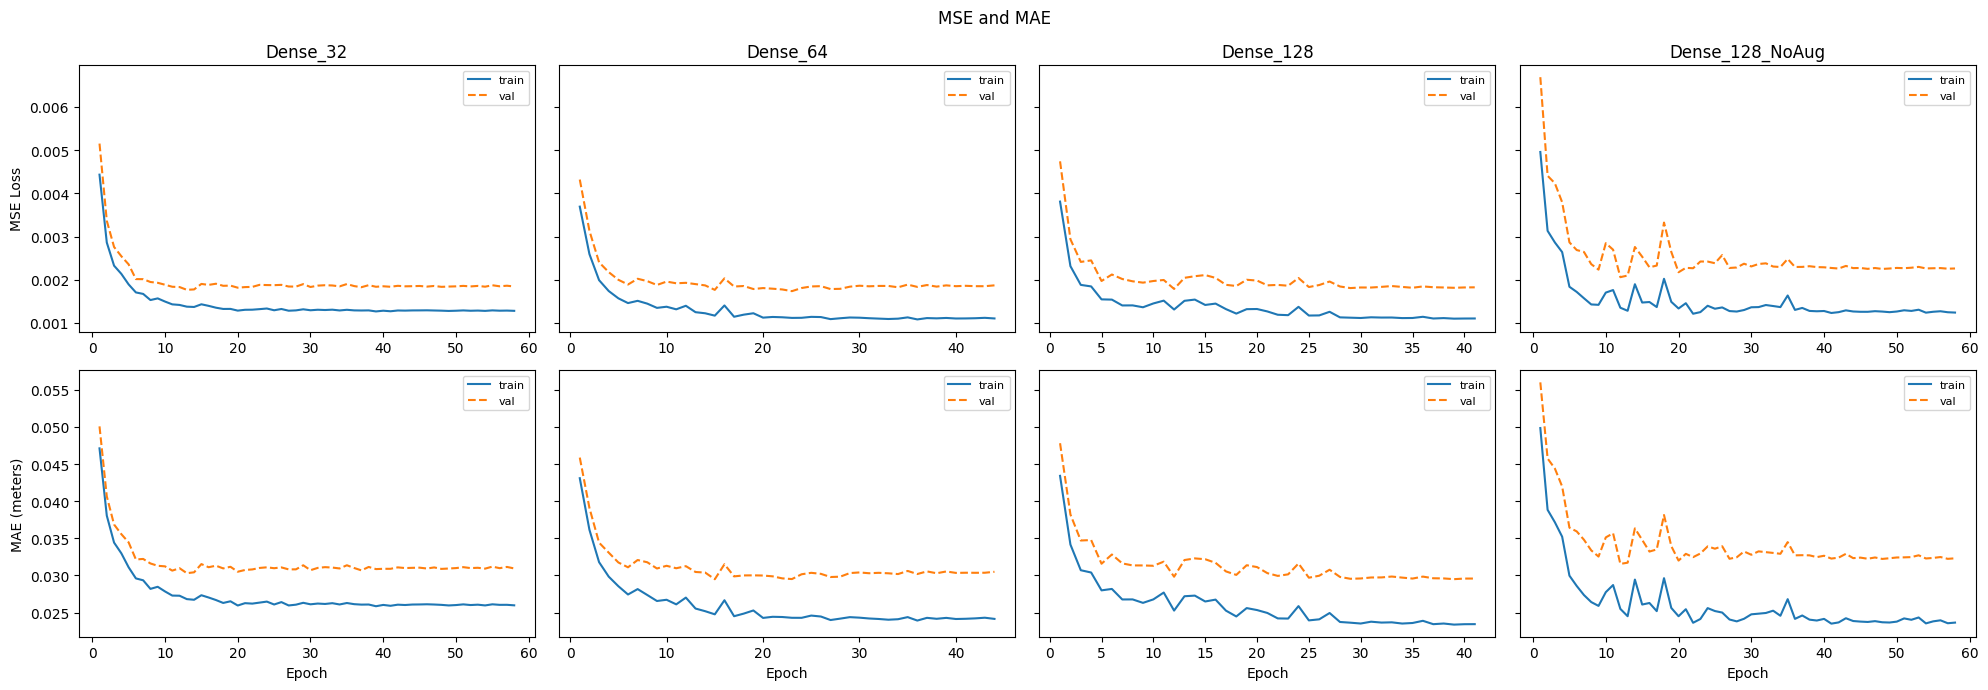

In [16]:
fig, axes = plt.subplots(2, len(MODEL_CONFIGS), figsize=(5 * len(MODEL_CONFIGS), 7), sharey="row")

for col, cfg in enumerate(MODEL_CONFIGS):
    variant  = cfg["model_variant"]
    histories = all_histories[variant]

    max_ep = max(len(h["train_loss"]) for h in histories)

    def mean_curve(key):
        padded = [h[key] + [h[key][-1]] * (max_ep - len(h[key])) for h in histories]
        return np.mean(padded, axis=0)

    epochs = range(1, max_ep + 1)

    axes[0][col].plot(epochs, mean_curve("train_loss"), label="train")
    axes[0][col].plot(epochs, mean_curve("val_loss"),   label="val", linestyle="--")
    axes[0][col].set_title(variant)
    axes[0][col].set_ylabel("MSE Loss" if col == 0 else "")
    axes[0][col].legend(fontsize=8)

    axes[1][col].plot(epochs, mean_curve("train_mae"), label="train")
    axes[1][col].plot(epochs, mean_curve("val_mae"),   label="val", linestyle="--")
    axes[1][col].set_xlabel("Epoch")
    axes[1][col].set_ylabel("MAE (meters)" if col == 0 else "")
    axes[1][col].legend(fontsize=8)

plt.suptitle("MSE and MAE")
plt.tight_layout()
plt.show()

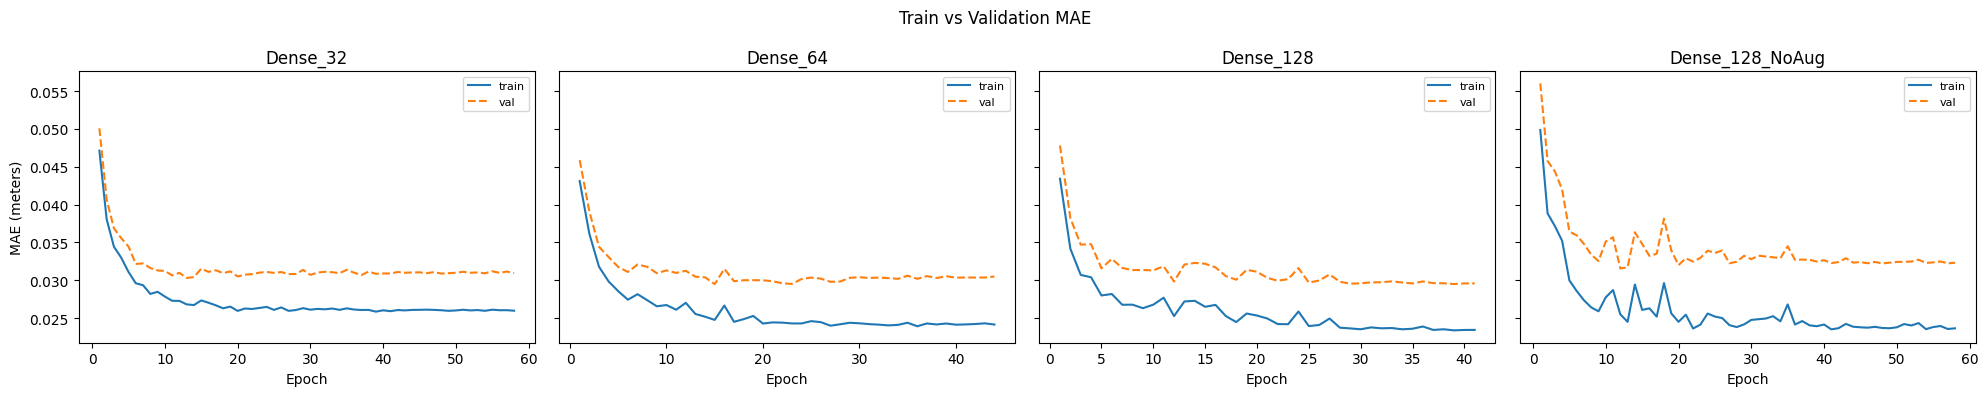

In [17]:
fig, axes = plt.subplots(1, len(MODEL_CONFIGS), figsize=(5 * len(MODEL_CONFIGS), 4), sharey=True)

for ax, cfg in zip(axes, MODEL_CONFIGS):
    variant   = cfg["model_variant"]
    histories = all_histories[variant]
    max_ep    = max(len(h["train_mae"]) for h in histories)

    def mean_curve(key):
        padded = [h[key] + [h[key][-1]] * (max_ep - len(h[key])) for h in histories]
        return np.mean(padded, axis=0)

    epochs = range(1, max_ep + 1)
    ax.plot(epochs, mean_curve("train_mae"), label="train")
    ax.plot(epochs, mean_curve("val_mae"),   label="val", linestyle="--")
    ax.set_title(variant)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)

axes[0].set_ylabel("MAE (meters)")
plt.suptitle("Train vs Validation MAE")
plt.tight_layout()
plt.show()

In [18]:
for cfg in MODEL_CONFIGS:
    variant = cfg["model_variant"]
    sub = results_df[results_df["model_variant"] == variant]
    jdist = np.array(sub["joint_dist_cm"].tolist()).mean(axis=0)
    print(f"\n{variant}  MAE={sub['mae_cm'].mean():.3f} cm  dist={sub['mean_dist_cm'].mean():.3f} cm")
    for j, d in zip(JOINTS, jdist):
        print(f"  {j:20s} {d:.3f} cm")


Dense_32  MAE=3.158 cm  dist=5.105 cm
  head                 4.954 cm
  left_shoulder        4.684 cm
  left_elbow           5.474 cm
  right_shoulder       4.716 cm
  right_elbow          5.418 cm
  left_hand            6.651 cm
  right_hand           6.591 cm
  left_hip             4.261 cm
  right_hip            4.277 cm
  left_knee            4.832 cm
  right_knee           4.857 cm
  left_foot            4.837 cm
  right_foot           4.809 cm

Dense_64  MAE=3.038 cm  dist=4.917 cm
  head                 4.799 cm
  left_shoulder        4.503 cm
  left_elbow           5.163 cm
  right_shoulder       4.512 cm
  right_elbow          5.207 cm
  left_hand            6.379 cm
  right_hand           6.378 cm
  left_hip             4.185 cm
  right_hip            4.199 cm
  left_knee            4.837 cm
  right_knee           4.751 cm
  left_foot            4.548 cm
  right_foot           4.457 cm

Dense_128  MAE=3.058 cm  dist=4.949 cm
  head                 4.868 cm
  left_shoulder   

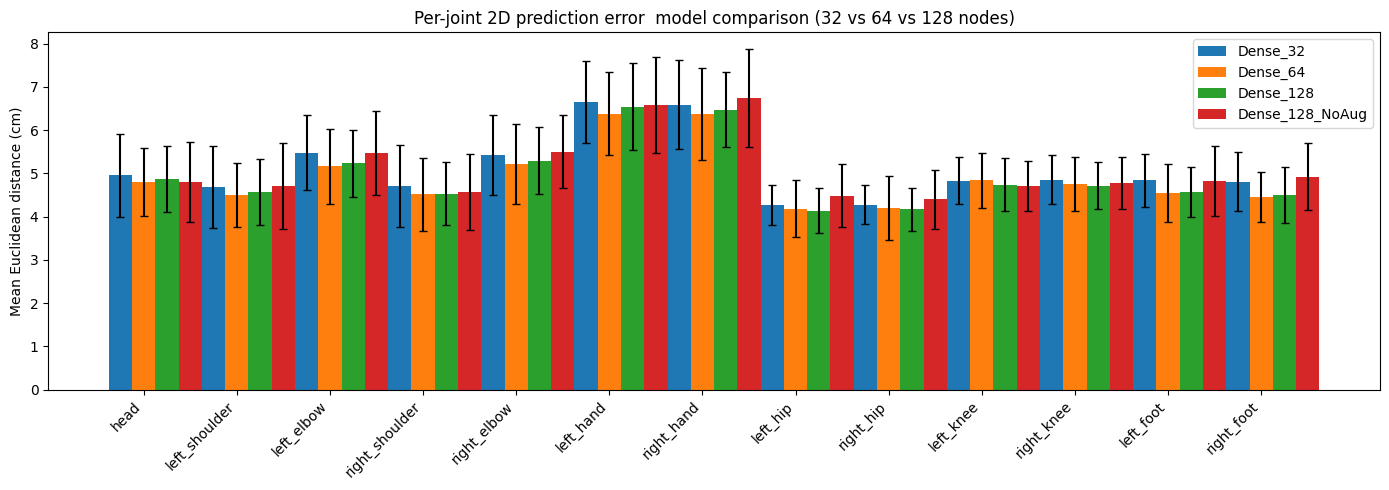

In [19]:
variants = [c["model_variant"] for c in MODEL_CONFIGS]
x = np.arange(len(JOINTS))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 5))
for i, variant in enumerate(variants):
    sub = results_df[results_df["model_variant"] == variant]
    jdist_mean = np.array(sub["joint_dist_cm"].tolist()).mean(axis=0)
    jdist_std  = np.array(sub["joint_dist_cm"].tolist()).std(axis=0)
    ax.bar(x + i * width, jdist_mean, width, label=variant, yerr=jdist_std, capsize=3)

ax.set_xticks(x + width)
ax.set_xticklabels(JOINTS, rotation=45, ha="right")
ax.set_ylabel("Mean Euclidean distance (cm)")
ax.set_title("Per-joint 2D prediction error  model comparison (32 vs 64 vs 128 nodes)")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
best_variant = results_df.groupby("model_variant")["mean_dist_cm"].mean().idxmin()
best_cfg = next(c for c in MODEL_CONFIGS if c["model_variant"] == best_variant)
print(f"Best model: {best_variant}")

tr_idx_f, val_idx_f = train_test_split(
    np.arange(len(X)), test_size=VALIDATION_SPLIT, random_state=RANDOM_SEED)

final_scaler = fit_scaler(X[tr_idx_f])
X_tr_f  = apply_scaler(X[tr_idx_f],  final_scaler)
X_val_f = apply_scaler(X[val_idx_f], final_scaler)

final_model = DensePoseRegressor(
    SEQ_LEN, len(INPUT_FEATURES), len(TARGET_FEATURES),
    hidden_units=best_cfg["hidden_units"], dropout=best_cfg["dropout"])

final_model, final_hist, final_val_loss, final_epoch = train_model(
    final_model,
    make_loader(X_tr_f,  y[tr_idx_f],  True),
    make_loader(X_val_f, y[val_idx_f], False))

model_path  = Path("A10_model.pt")
scaler_path = Path("A10_scaler.npz")
meta_path   = Path("A10_metadata.json")

torch.save(final_model.state_dict(), model_path)
np.savez(scaler_path, mean=final_scaler.mean_, scale=final_scaler.scale_)

meta = {"model_variant": best_variant,
        "seq_len": SEQ_LEN,
        "input_features": INPUT_FEATURES,
        "target_features": TARGET_FEATURES,
        "target_unit": TARGET_UNIT,
        "mean_cv_dist_cm": float(results_df[results_df["model_variant"] == best_variant]["mean_dist_cm"].mean()),
        "final_best_epoch": int(final_epoch),
        "config": {k: list(v) if isinstance(v, tuple) else v for k, v in best_cfg.items()}}
with open(meta_path, "w") as f: json.dump(meta, f, indent=2)

print("Saved:", model_path, scaler_path, meta_path)

Best model: Dense_64
Saved: A10_model.pt A10_scaler.npz A10_metadata.json


In [21]:
import json, numpy as np, torch, torch.nn as nn, pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler

# ── Model definition (must match training) ───────────────────────────────────
class DensePoseRegressor(nn.Module):
    def __init__(self, seq_len, n_in, n_out, hidden_units=(64,), dropout=0.0):
        super().__init__()
        layers, prev = [], seq_len * n_in
        for h in hidden_units:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0: layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, seq_len * n_out))
        self.net = nn.Sequential(*layers)
        self.seq_len, self.n_out = seq_len, n_out

    def forward(self, x):
        b = x.shape[0]
        return self.net(x.reshape(b, -1)).reshape(b, self.seq_len, self.n_out)

# ── Load metadata ─────────────────────────────────────────────────────────────
with open("A10_metadata.json") as f:
    meta = json.load(f)

SEQ_LEN         = meta["seq_len"]
INPUT_FEATURES  = meta["input_features"]
TARGET_FEATURES = meta["target_features"]
hidden_units    = tuple(meta["config"]["hidden_units"])

# ── Load model weights ────────────────────────────────────────────────────────
model = DensePoseRegressor(SEQ_LEN, len(INPUT_FEATURES), len(TARGET_FEATURES),
                           hidden_units=hidden_units)
model.load_state_dict(torch.load("A10_model.pt", map_location="cpu"))
model.eval()

# ── Load scaler ───────────────────────────────────────────────────────────────
npz = np.load("A10_scaler.npz")
scaler = StandardScaler()
scaler.mean_  = npz["mean"]
scaler.scale_ = npz["scale"]

# ── Inference helper ──────────────────────────────────────────────────────────
MOVENET_TO_STANDARD = {
    "nose": "head", "left_wrist": "left_hand", "right_wrist": "right_hand",
    "left_ankle": "left_foot", "right_ankle": "right_foot",
}

def predict_from_movenet(frames_df):
    """frames_df: DataFrame with 20 MoveNet rows. Returns Kinect coords in meters."""
    df = frames_df.copy()
    rename = {f"{old}_{ax}": f"{new}_{ax}"
              for old, new in MOVENET_TO_STANDARD.items() for ax in ["x", "y"]}
    df = df.rename(columns=rename)
    pn_rename = {f"{j}_{ax}": f"{j}_pn_{ax}"
                 for j in [c.replace("_pn_x","").replace("_pn_y","") for c in INPUT_FEATURES[::2]]
                 for ax in ["x", "y"]}
    df = df.rename(columns=pn_rename)
    x = df[INPUT_FEATURES].to_numpy(dtype=np.float32)
    x = scaler.transform(x).reshape(1, SEQ_LEN, -1)
    with torch.no_grad():
        pred = model(torch.tensor(x)).numpy()
    return pd.DataFrame(pred[0], columns=TARGET_FEATURES)

# ── Example ───────────────────────────────────────────────────────────────────
sample = movenet_raw[movenet_raw["seq_key"] == "A1"].head(20)
result = predict_from_movenet(sample)
print(result[["head_x", "head_y", "left_shoulder_x", "left_shoulder_y"]].round(4))


    head_x  head_y  left_shoulder_x  left_shoulder_y
0   0.0133  0.6848          -0.1376           0.4475
1   0.0120  0.6800          -0.1385           0.4408
2   0.0103  0.6762          -0.1392           0.4331
3   0.0087  0.6731          -0.1398           0.4257
4   0.0072  0.6716          -0.1397           0.4188
5   0.0063  0.6707          -0.1391           0.4135
6   0.0055  0.6729          -0.1383           0.4106
7   0.0050  0.6760          -0.1378           0.4118
8   0.0049  0.6821          -0.1372           0.4134
9   0.0048  0.6894          -0.1370           0.4165
10  0.0048  0.6965          -0.1369           0.4197
11  0.0046  0.7053          -0.1367           0.4242
12  0.0048  0.7137          -0.1367           0.4311
13  0.0056  0.7236          -0.1365           0.4399
14  0.0070  0.7339          -0.1358           0.4484
15  0.0084  0.7425          -0.1353           0.4550
16  0.0099  0.7497          -0.1352           0.4608
17  0.0114  0.7538          -0.1348           

### Encapsulate moden in PythonModel

In [23]:
import mlflow.pyfunc


class DensePoseRegressor(nn.Module):
    """
    Must match the architecture used during training.
    """

    def __init__(self, seq_len, n_in, n_out, hidden_units=(64,), dropout=0.0):
        super().__init__()

        layers = []
        prev = seq_len * n_in

        for h in hidden_units:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h

        layers.append(nn.Linear(prev, seq_len * n_out))

        self.net = nn.Sequential(*layers)
        self.seq_len = seq_len
        self.n_out = n_out

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        y = self.net(x)
        return y.reshape(batch_size, self.seq_len, self.n_out)


class MoveNetDataFramePythonModel(mlflow.pyfunc.PythonModel):
    """
    MLflow pyfunc model for inference from a MoveNet DataFrame.

    Input:
        pandas.DataFrame containing MoveNet frame-level pose columns.

    Output:
        pandas.DataFrame containing one prediction row per input frame.
    """

    MOVENET_TO_STANDARD = {
        "nose": "head",
        "left_wrist": "left_hand",
        "right_wrist": "right_hand",
        "left_ankle": "left_foot",
        "right_ankle": "right_foot",
    }

    DROP_COLUMNS = {"timestamp_ms"}

    def load_context(self, context):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        with open(context.artifacts["metadata"], "r") as f:
            self.meta = json.load(f)

        self.seq_len = int(self.meta["seq_len"])
        self.input_features = self.meta["input_features"]
        self.target_features = self.meta["target_features"]

        config = self.meta.get("config", {})
        hidden_units = tuple(config.get("hidden_units", [64]))
        dropout = float(config.get("dropout", 0.0))

        self.model = DensePoseRegressor(
            seq_len=self.seq_len,
            n_in=len(self.input_features),
            n_out=len(self.target_features),
            hidden_units=hidden_units,
            dropout=dropout,
        )

        state_dict = torch.load(
            context.artifacts["model_state"],
            map_location=self.device,
        )

        self.model.load_state_dict(state_dict)
        self.model.to(self.device)
        self.model.eval()

        scaler_npz = np.load(context.artifacts["scaler"])
        self.scaler_mean = scaler_npz["mean"].astype(np.float32)
        self.scaler_scale = scaler_npz["scale"].astype(np.float32)

    def predict(self, context, model_input):
        if not isinstance(model_input, pd.DataFrame):
            raise TypeError(
                "MoveNetDataFramePythonModel expects model_input to be a pandas DataFrame."
            )

        movenet_df = self._prepare_movenet_dataframe(model_input)

        if len(movenet_df) < self.seq_len:
            raise ValueError(
                f"MoveNet input has {len(movenet_df)} rows, "
                f"but the model requires at least {self.seq_len} frames."
            )

        if "frameno" in movenet_df.columns:
            frame_index = movenet_df["frameno"].to_numpy()
        else:
            frame_index = np.arange(len(movenet_df))

        x_frames = movenet_df[self.input_features].to_numpy(dtype=np.float32)

        windows, starts = self._make_windows(x_frames)
        windows_scaled = self._scale_windows(windows)

        with torch.no_grad():
            x_tensor = torch.tensor(
                windows_scaled,
                dtype=torch.float32,
                device=self.device,
            )
            pred_windows = self.model(x_tensor).cpu().numpy()

        frame_predictions = self._average_overlapping_windows(
            pred_windows=pred_windows,
            starts=starts,
            n_frames=len(movenet_df),
        )

        output = pd.DataFrame(frame_predictions, columns=self.target_features)
        output.insert(0, "prediction_count", self._prediction_counts(starts, len(movenet_df)))
        output.insert(0, "frame_index", frame_index)

        return output

    def _prepare_movenet_dataframe(self, df):
        df = df.copy()

        df.columns = [
            c.strip().lower().replace(" ", "_").replace("-", "_")
            for c in df.columns
        ]

        score_cols = [c for c in df.columns if c.endswith("_score")]
        df = df.drop(columns=score_cols + list(self.DROP_COLUMNS), errors="ignore")

        rename_map = {}
        for old_joint, new_joint in self.MOVENET_TO_STANDARD.items():
            for axis in ["x", "y"]:
                rename_map[f"{old_joint}_{axis}"] = f"{new_joint}_{axis}"

        df = df.rename(columns=rename_map)

        pn_rename = {}
        for feature in self.input_features:
            joint, axis = feature.rsplit("_pn_", 1)
            raw_col = f"{joint}_{axis}"
            if raw_col in df.columns:
                pn_rename[raw_col] = feature

        df = df.rename(columns=pn_rename)

        missing = [col for col in self.input_features if col not in df.columns]
        if missing:
            raise ValueError(
                "MoveNet DataFrame is missing required model input columns. "
                f"First missing columns: {missing[:10]}"
            )

        df = df.dropna(subset=self.input_features).reset_index(drop=True)

        return df

    def _make_windows(self, x_frames):
        windows = []
        starts = []

        for start in range(0, len(x_frames) - self.seq_len + 1):
            end = start + self.seq_len
            windows.append(x_frames[start:end])
            starts.append(start)

        return (
            np.asarray(windows, dtype=np.float32),
            np.asarray(starts, dtype=np.int64),
        )

    def _scale_windows(self, windows):
        original_shape = windows.shape
        flat = windows.reshape(-1, original_shape[-1])

        scaled = (flat - self.scaler_mean) / self.scaler_scale

        return scaled.reshape(original_shape).astype(np.float32)

    def _average_overlapping_windows(self, pred_windows, starts, n_frames):
        sums = np.zeros((n_frames, len(self.target_features)), dtype=np.float32)
        counts = np.zeros(n_frames, dtype=np.float32)

        for window_pred, start in zip(pred_windows, starts):
            end = start + self.seq_len
            sums[start:end] += window_pred
            counts[start:end] += 1.0

        counts = np.maximum(counts, 1.0)

        return sums / counts[:, None]

    def _prediction_counts(self, starts, n_frames):
        counts = np.zeros(n_frames, dtype=np.int64)

        for start in starts:
            end = start + self.seq_len
            counts[start:end] += 1

        return counts

/Users/pettergustafsson/study/4DT907/project_dir/ml/models/venv/lib/python3.11/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [26]:
# import ml creds
load_dotenv("../../../ml.env")
mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI"))

In [28]:
artifacts = {
    "model_state": "A10_model.pt",
    "scaler": "A10_scaler.npz",
    "metadata": "A10_metadata.json",
}

mlflow.set_experiment("A10_posenet_to_kinect2d")

with mlflow.start_run(run_name="logging_movenet_to_kinect_model"):
    mlflow.pyfunc.log_model(
        name="model",
        python_model=MoveNetDataFramePythonModel(),
        artifacts=artifacts,
        pip_requirements=[
            "mlflow",
            "torch",
            "numpy",
            "pandas",
        ],
    )

🏃 View run logging_movenet_to_kinect_model at: https://172.27.62.170:5001/#/experiments/25/runs/29c66e4230844ec7a71562ff1dec221e
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/25


In [29]:
# load model
model = mlflow.pyfunc.load_model("models:/m-c0b039396d494a618d60c6a8026edee5")

In [ ]:
# load movenet
movenet_file = pd.read_csv(MOVENET_DIR / "A1.csv")
movenet_file


,timestamp_ms,frame_index,nose_x,nose_y,nose_score,left_eye_x,left_eye_y,left_eye_score,right_eye_x,right_eye_y,...,left_knee_score,right_knee_x,right_knee_y,right_knee_score,left_ankle_x,left_ankle_y,left_ankle_score,right_ankle_x,right_ankle_y,right_ankle_score
0,0,0,993.07,254.03,0.5925,1007.84,242.59,0.5830,974.67,242.76,...,0.4367,898.88,795.75,0.6022,1053.61,987.20,0.5770,893.85,993.23,0.6112
1,67,1,991.21,256.81,0.5695,1005.45,244.78,0.6140,973.69,245.43,...,0.4279,899.03,795.98,0.5734,1053.80,986.89,0.5821,892.38,992.17,0.6116
2,133,2,990.47,254.91,0.5332,1004.97,243.26,0.5833,972.93,243.73,...,0.4029,898.47,797.13,0.5812,1055.37,988.47,0.5140,902.74,979.58,0.4692
3,200,3,990.90,256.25,0.5602,1005.34,244.18,0.6004,973.42,244.77,...,0.3807,897.93,794.30,0.5453,1054.11,983.71,0.5806,893.59,987.46,0.6358
4,267,4,992.43,253.66,0.5658,1006.76,242.49,0.5644,974.97,242.81,...,0.3726,899.22,796.75,0.5491,1054.14,988.56,0.4953,892.88,989.43,0.6483
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
224,14933,224,1510.13,122.43,0.5731,1514.96,100.48,0.7614,1499.46,83.58,...,0.5213,1310.92,801.62,0.4364,1314.81,968.02,0.3804,1327.27,1052.93,0.4588
225,15000,225,1504.89,119.00,0.4260,1513.89,98.85,0.6897,1494.35,82.70,...,0.4700,1304.91,773.02,0.6131,1334.70,968.73,0.4040,1333.29,1054.60,0.4404
226,15067,226,1505.04,118.71,0.4183,1515.07,98.38,0.6844,1494.17,81.74,...,0.4577,1314.16,790.16,0.5294,1337.50,968.03,0.3423,1333.51,1048.66,0.4973
227,15133,227,1503.26,119.45,0.3986,1513.91,100.66,0.7450,1492.33,81.50,...,0.4940,1334.15,798.01,0.5810,1335.89,997.65,0.3666,1331.08,1042.13,0.5361


In [ ]:
# test prediction
result = model.predict(movenet_file)
result

,frame_index,prediction_count,head_x,head_y,left_shoulder_x,left_shoulder_y,left_elbow_x,left_elbow_y,right_shoulder_x,right_shoulder_y,...,right_hip_x,right_hip_y,left_knee_x,left_knee_y,right_knee_x,right_knee_y,left_foot_x,left_foot_y,right_foot_x,right_foot_y
0,0,1,0.013310,0.684805,-0.137556,0.447492,-0.232205,0.199113,0.175375,0.455189,...,0.105701,0.104647,-0.131492,-0.353465,0.159453,-0.334922,-0.127816,-0.746573,0.138394,-0.721587
1,1,2,0.013155,0.667158,-0.136669,0.431706,-0.232077,0.182745,0.174431,0.437843,...,0.106117,0.090681,-0.137565,-0.357263,0.162312,-0.336247,-0.127664,-0.746623,0.139922,-0.722409
2,2,3,0.013812,0.656601,-0.135113,0.420938,-0.231617,0.173753,0.174468,0.426540,...,0.107120,0.078403,-0.143022,-0.361180,0.165720,-0.336869,-0.127738,-0.746595,0.142073,-0.721060
3,3,4,0.014413,0.647339,-0.134092,0.410798,-0.231093,0.165298,0.174509,0.416135,...,0.107971,0.065419,-0.147474,-0.365750,0.167881,-0.339732,-0.127037,-0.748243,0.143521,-0.721775
4,4,5,0.014863,0.640336,-0.133288,0.402099,-0.230596,0.159779,0.174544,0.407380,...,0.109018,0.051676,-0.151373,-0.371621,0.169713,-0.344565,-0.126350,-0.750620,0.144580,-0.724202
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
224,224,5,0.171289,1.353450,-0.010742,0.892306,0.070307,0.780048,0.313907,1.032431,...,0.279917,0.466392,0.050016,-0.237856,0.245575,-0.234658,0.079489,-0.446507,0.025708,-0.543566
225,225,4,0.172368,1.359601,-0.009935,0.896994,0.063750,0.784985,0.314936,1.038934,...,0.282268,0.469191,0.049239,-0.235753,0.245080,-0.235499,0.078395,-0.441199,0.023253,-0.542298
226,226,3,0.172140,1.360938,-0.010083,0.897816,0.056011,0.785938,0.314541,1.041206,...,0.282762,0.468630,0.050296,-0.240663,0.241161,-0.241110,0.078031,-0.443548,0.019766,-0.543883
227,227,2,0.170327,1.360240,-0.011437,0.896265,0.046935,0.782173,0.312872,1.040617,...,0.282397,0.463520,0.051889,-0.253238,0.235323,-0.251257,0.079782,-0.455037,0.015428,-0.550556


In [33]:
# save csv
result.to_csv("test.csv", index=False)